In [ ]:

!pip install ucimlrepo


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

credit_data = fetch_ucirepo(id=350)

X = credit_data.data.features
y = credit_data.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (30000, 24)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:

# Rename dataset columns
new_columns = {
    "X1": "LIMIT_BAL",
    "X2": "SEX",
    "X3": "EDUCATION",
    "X4": "MARRIAGE",
    "X5": "AGE",
    "X6": "PAY_0",
    "X7": "PAY_2",
    "X8": "PAY_3",
    "X9": "PAY_4",
    "X10": "PAY_5",
    "X11": "PAY_6",
    "X12": "BILL_AMT1",
    "X13": "BILL_AMT2",
    "X14": "BILL_AMT3",
    "X15": "BILL_AMT4",
    "X16": "BILL_AMT5",
    "X17": "BILL_AMT6",
    "X18": "PAY_AMT1",
    "X19": "PAY_AMT2",
    "X20": "PAY_AMT3",
    "X21": "PAY_AMT4",
    "X22": "PAY_AMT5",
    "X23": "PAY_AMT6",
    "Y": "DEFAULT"
}

df.rename(columns=new_columns, inplace=True)

print("Updated column names:")
print(df.columns.tolist())

df.head()


Updated column names:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'DEFAULT']


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [ ]:

print("Default distribution:")
print(df["DEFAULT"].value_counts())

print("\nDefault percentage:")
print(
    df["DEFAULT"].value_counts(normalize=True) * 100
)


Default distribution:
DEFAULT
0    23364
1     6636
Name: count, dtype: int64

Default percentage:
DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64


In [ ]:

print("Dataset dimensions:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

print("\nData types:")
print(df.dtypes)


Dataset dimensions: (30000, 24)

Missing values:
0

Duplicate records:
35

Data types:
LIMIT_BAL    int64
SEX          int64
EDUCATION    int64
MARRIAGE     int64
AGE          int64
PAY_0        int64
PAY_2        int64
PAY_3        int64
PAY_4        int64
PAY_5        int64
PAY_6        int64
BILL_AMT1    int64
BILL_AMT2    int64
BILL_AMT3    int64
BILL_AMT4    int64
BILL_AMT5    int64
BILL_AMT6    int64
PAY_AMT1     int64
PAY_AMT2     int64
PAY_AMT3     int64
PAY_AMT4     int64
PAY_AMT5     int64
PAY_AMT6     int64
DEFAULT      int64
dtype: object


In [ ]:

duplicate_rows = df[df.duplicated(keep=False)]

print("Total rows involved in duplicates:",
      len(duplicate_rows))

duplicate_rows.head(10)


Total rows involved in duplicates: 70


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
18,360000,2,1,1,49,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
627,230000,1,1,1,39,-1,-1,-1,-1,-1,...,660,660,660,660,660,660,660,660,660,0
839,500000,1,1,1,43,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1093,360000,1,2,1,41,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1211,160000,2,3,2,26,-1,-1,-1,-1,-1,...,390,390,390,390,390,390,390,390,390,0
1601,150000,2,1,1,31,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1759,50000,1,2,2,26,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0
1964,150000,2,1,1,38,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
1980,150000,2,1,1,38,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,1
2621,210000,2,1,2,39,1,-2,-2,-2,-2,...,0,0,0,0,0,0,0,0,0,0


In [ ]:

df_clean = df.drop_duplicates().copy()

print("Original records:", len(df))
print("Records after removing duplicates:", len(df_clean))
print("Records removed:", len(df) - len(df_clean))


Original records: 30000
Records after removing duplicates: 29965
Records removed: 35


In [ ]:

# Count default and non-default customers
default_counts = df["DEFAULT"].value_counts().sort_index()

print("Customer distribution:")
print(default_counts)

# Calculate percentages
default_percentages = (
    df["DEFAULT"].value_counts(normalize=True).sort_index() * 100
)

print("\nCustomer percentages:")
print(default_percentages)

# Calculate default rate
default_rate = df["DEFAULT"].mean() * 100

print("\nOverall default rate:", round(default_rate, 2), "%")


Customer distribution:
DEFAULT
0    23364
1     6636
Name: count, dtype: int64

Customer percentages:
DEFAULT
0    77.88
1    22.12
Name: proportion, dtype: float64

Overall default rate: 22.12 %


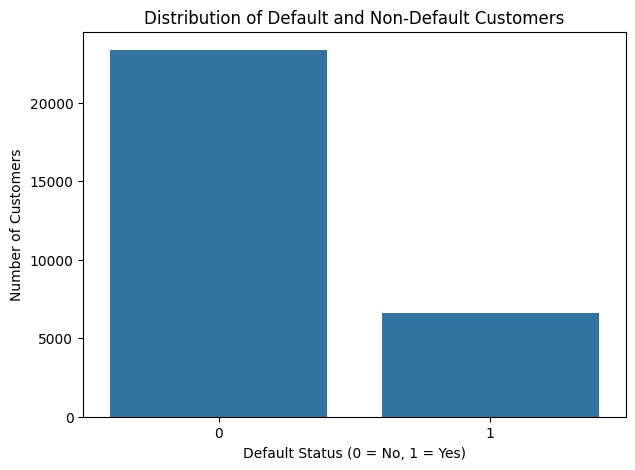

In [ ]:

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="DEFAULT")

plt.title("Distribution of Default and Non-Default Customers")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

plt.show()


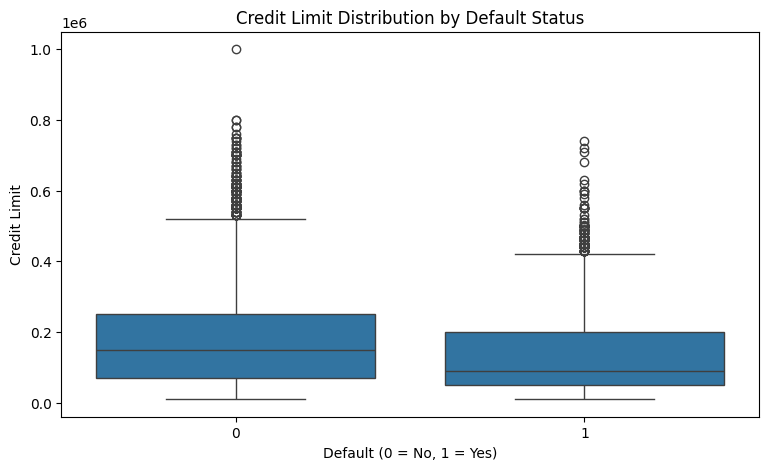

In [ ]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="DEFAULT",
    y="LIMIT_BAL"
)

plt.title("Credit Limit Distribution by Default Status")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Credit Limit")

plt.show()


In [ ]:

print(
    df.groupby("DEFAULT")["LIMIT_BAL"]
      .agg(["mean", "median", "min", "max"])
)


                  mean    median    min      max
DEFAULT                                         
0        178099.726074  150000.0  10000  1000000
1        130109.656420   90000.0  10000   740000


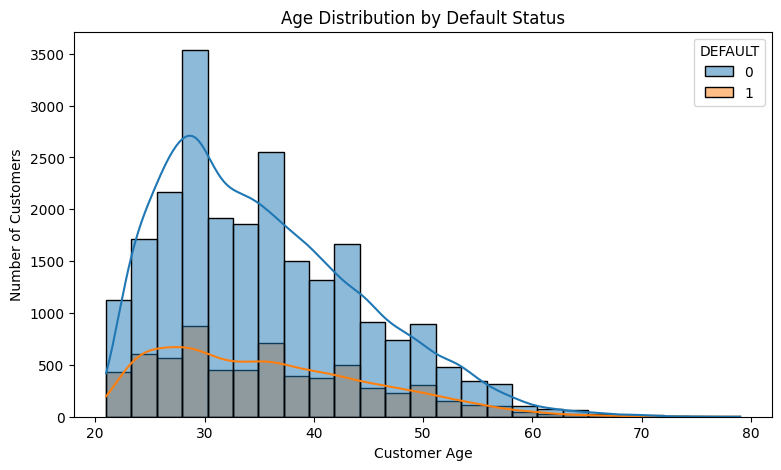

In [ ]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="AGE",
    hue="DEFAULT",
    bins=25,
    multiple="layer",
    kde=True
)

plt.title("Age Distribution by Default Status")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.show()


In [ ]:

df["AGE_GROUP"] = pd.cut(
    df["AGE"],
    bins=[20, 30, 40, 50, 60, 80],
    labels=["20-29", "30-39", "40-49", "50-59", "60+"],
    right=False
)

age_default = (
    df.groupby("AGE_GROUP", observed=False)["DEFAULT"]
      .agg(["count", "mean"])
)

age_default["default_rate"] = age_default["mean"] * 100

print(age_default)


           count      mean  default_rate
AGE_GROUP                               
20-29       9618  0.228426     22.842587
30-39      11238  0.202527     20.252714
40-49       6464  0.229734     22.973391
50-59       2341  0.248612     24.861170
60+          339  0.283186     28.318584


In [ ]:

repayment_default = (
    df.groupby("PAY_0")["DEFAULT"]
      .agg(["count", "mean"])
)

repayment_default["default_rate"] = (
    repayment_default["mean"] * 100
)

print(repayment_default)


       count      mean  default_rate
PAY_0                               
-2      2759  0.132294     13.229431
-1      5686  0.167781     16.778051
 0     14737  0.128113     12.811291
 1      3688  0.339479     33.947939
 2      2667  0.691414     69.141357
 3       322  0.757764     75.776398
 4        76  0.684211     68.421053
 5        26  0.500000     50.000000
 6        11  0.545455     54.545455
 7         9  0.777778     77.777778
 8        19  0.578947     57.894737


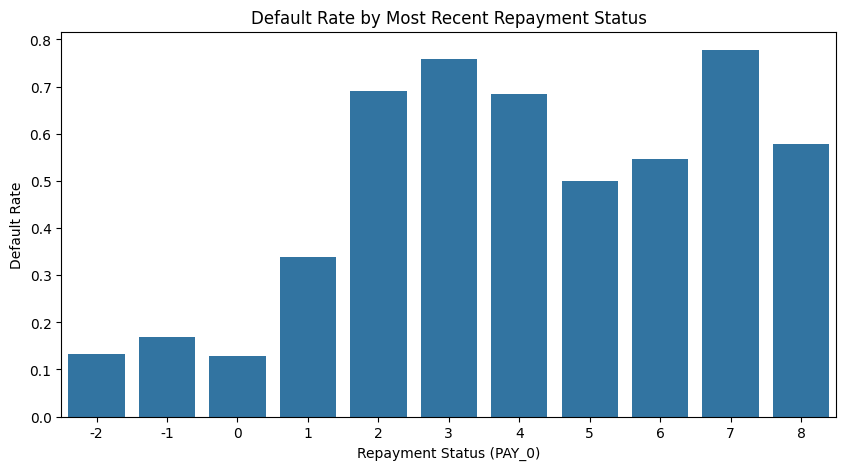

In [ ]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="PAY_0",
    y="DEFAULT",
    errorbar=None
)

plt.title("Default Rate by Most Recent Repayment Status")
plt.xlabel("Repayment Status (PAY_0)")
plt.ylabel("Default Rate")

plt.show()


In [ ]:

print(
    df.groupby("DEFAULT")["BILL_AMT1"]
      .agg(["mean", "median"])
)


                 mean   median
DEFAULT                       
0        51994.227273  23119.5
1        48509.162297  20185.0


In [ ]:

print(
    df.groupby("DEFAULT")["PAY_AMT1"]
      .agg(["mean", "median"])
)


                mean  median
DEFAULT                     
0        6307.337357  2459.5
1        3397.044153  1636.0


In [ ]:

# Calculate latest credit utilisation
df["CREDIT_UTILIZATION"] = (
    df["BILL_AMT1"] / df["LIMIT_BAL"]
)

print(df["CREDIT_UTILIZATION"].describe())


count    30000.000000
mean         0.423771
std          0.411462
min         -0.619892
25%          0.022032
50%          0.313994
75%          0.829843
max          6.455300
Name: CREDIT_UTILIZATION, dtype: float64


# **Number of months with delayed payments**

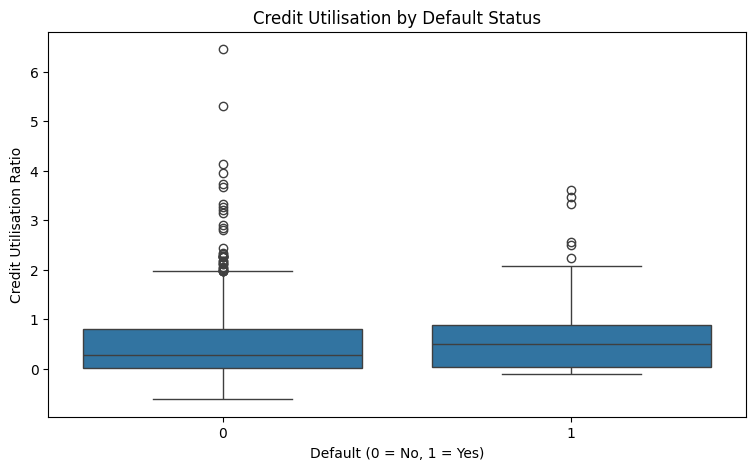

In [ ]:

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="DEFAULT",
    y="CREDIT_UTILIZATION"
)

plt.title("Credit Utilisation by Default Status")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Credit Utilisation Ratio")

plt.show()


In [ ]:

repayment_columns = [
    "PAY_0", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

df["DELAY_MONTHS"] = (
    (df[repayment_columns] > 0).sum(axis=1)
)

print("DELAY_MONTHS created successfully!")
print(df[["PAY_0", "PAY_2", "PAY_3",
          "PAY_4", "PAY_5", "PAY_6",
          "DELAY_MONTHS"]].head())


DELAY_MONTHS created successfully!
   PAY_0  PAY_2  PAY_3  PAY_4  PAY_5  PAY_6  DELAY_MONTHS
0      2      2     -1     -1     -2     -2             2
1     -1      2      0      0      0      2             2
2      0      0      0      0      0      0             0
3      0      0      0      0      0      0             0
4     -1      0     -1      0      0      0             0


In [ ]:

delay_default = (
    df.groupby("DELAY_MONTHS")["DEFAULT"]
      .agg(["count", "mean"])
)

delay_default["default_rate"] = (
    delay_default["mean"] * 100
)

print(delay_default)


              count      mean  default_rate
DELAY_MONTHS                               
0             19931  0.117104     11.710401
1              4426  0.298238     29.823769
2              1899  0.387572     38.757241
3              1154  0.508666     50.866551
4               951  0.573081     57.308097
5               298  0.573826     57.382550
6              1341  0.703207     70.320656


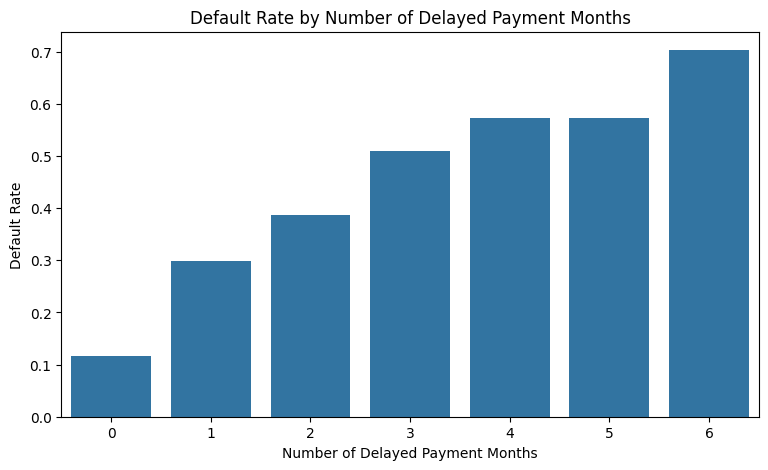

In [ ]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="DELAY_MONTHS",
    y="DEFAULT",
    errorbar=None
)

plt.title("Default Rate by Number of Delayed Payment Months")
plt.xlabel("Number of Delayed Payment Months")
plt.ylabel("Default Rate")

plt.show()


In [ ]:

print(delay_default[["count", "default_rate"]])


              count  default_rate
DELAY_MONTHS                     
0             19931     11.710401
1              4426     29.823769
2              1899     38.757241
3              1154     50.866551
4               951     57.308097
5               298     57.382550
6              1341     70.320656


In [ ]:
print(
    df.groupby("DEFAULT")["CREDIT_UTILIZATION"]
      .agg(["mean", "median", "min", "max"])
)


             mean    median       min       max
DEFAULT                                        
0        0.404876  0.267498 -0.619892  6.455300
1        0.490297  0.492875 -0.100000  3.609925


In [ ]:

df["PAYMENT_TO_BILL_RATIO"] = np.where(
    df["BILL_AMT1"] > 0,
    df["PAY_AMT1"] / df["BILL_AMT1"],
    np.nan
)

print("Payment-to-bill ratio created!")
print(df[["BILL_AMT1", "PAY_AMT1",
          "PAYMENT_TO_BILL_RATIO"]].head())


Payment-to-bill ratio created!
   BILL_AMT1  PAY_AMT1  PAYMENT_TO_BILL_RATIO
0       3913         0               0.000000
1       2682         0               0.000000
2      29239      1518               0.051917
3      46990      2000               0.042562
4       8617      2000               0.232099


In [ ]:

print(
    df.groupby("DEFAULT")["PAYMENT_TO_BILL_RATIO"]
      .agg(["mean", "median", "min", "max"])
)


             mean    median  min           max
DEFAULT                                       
0        2.026796  0.065849  0.0  11453.666667
1        0.880416  0.050254  0.0   1001.000000


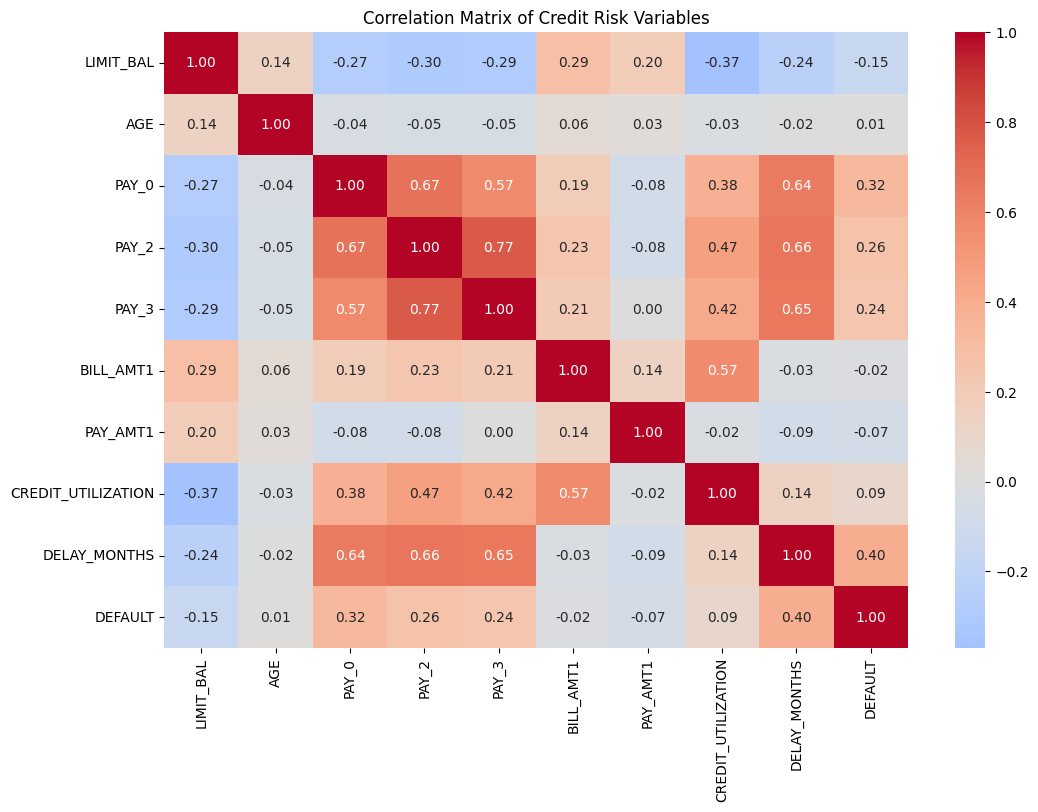

In [ ]:

correlation_columns = [
    "LIMIT_BAL", "AGE", "PAY_0", "PAY_2",
    "PAY_3", "BILL_AMT1", "PAY_AMT1",
    "CREDIT_UTILIZATION", "DELAY_MONTHS", "DEFAULT"
]

corr_matrix = df[correlation_columns].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Credit Risk Variables")
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Modelling libraries imported successfully!")


Modelling libraries imported successfully!


In [ ]:

# Select the original 23 predictor columns
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]

engineered_columns = [
    "AGE_GROUP",
    "CREDIT_UTILIZATION",
    "DELAY_MONTHS",
    "PAYMENT_TO_BILL_RATIO"
]

X = df.drop(
    columns=["DEFAULT"] + engineered_columns,
    errors="ignore"
).copy()

y = df["DEFAULT"].copy()

numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Number of predictors:", X.shape[1])
print("Number of records:", X.shape[0])
print("Categorical features:", categorical_features)
print("Numerical features:", len(numerical_features))

print("\nPredictor columns:")
print(X.columns.tolist())


Number of predictors: 23
Number of records: 30000
Categorical features: ['SEX', 'EDUCATION', 'MARRIAGE']
Numerical features: 20

Predictor columns:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining default distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting default distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training records: 24000
Testing records: 6000

Training default distribution:
DEFAULT
0    77.879167
1    22.120833
Name: proportion, dtype: float64

Testing default distribution:
DEFAULT
0    77.883333
1    22.116667
Name: proportion, dtype: float64


In [ ]:

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created!")


Preprocessing pipeline created!


In [ ]:

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


In [ ]:

# Predict probabilities of default
y_prob = logistic_model.predict_proba(X_test)[:, 1]

# Classify using 0.5 threshold
y_pred = (y_prob >= 0.5).astype(int)

print("Predictions generated!")
print("\nFirst 10 predicted probabilities:")
print(y_prob[:10])

print("\nFirst 10 predicted classes:")
print(y_pred[:10])


Predictions generated!

First 10 predicted probabilities:
[0.10605847 0.11819566 0.22042474 0.09581139 0.0294975  0.20673123
 0.13177364 0.16049173 0.07621891 0.20087241]

First 10 predicted classes:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:

print("ACCURACY:",
      accuracy_score(y_test, y_pred))

print("PRECISION:",
      precision_score(y_test, y_pred))

print("RECALL:",
      recall_score(y_test, y_pred))

print("F1 SCORE:",
      f1_score(y_test, y_pred))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))


ACCURACY: 0.8086666666666666
PRECISION: 0.6908315565031983
RECALL: 0.24415975885455915
F1 SCORE: 0.36080178173719374
ROC-AUC: 0.7098564102878357

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.82      0.97      0.89      4673
           1       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.75      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000



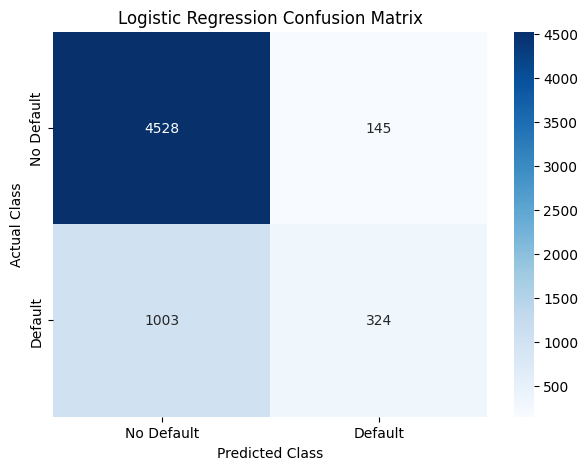

In [ ]:

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Logistic Regression Confusion Matrix")

plt.show()


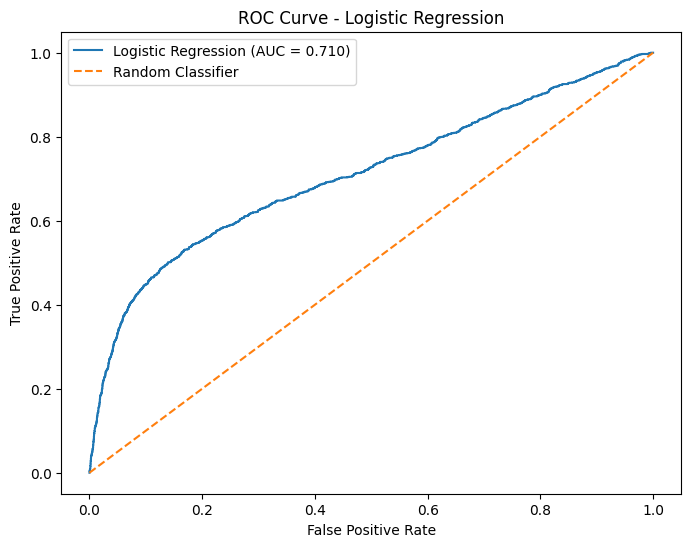

ROC-AUC: 0.7098564102878357


In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

print("ROC-AUC:", auc_score)


In [ ]:

from sklearn.metrics import precision_score, recall_score, f1_score

thresholds_to_test = [0.50, 0.40, 0.30, 0.20]

for threshold in thresholds_to_test:

    predictions = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)

    print("Precision:",
          round(precision_score(y_test, predictions), 4))

    print("Recall:",
          round(recall_score(y_test, predictions), 4))

    print("F1 Score:",
          round(f1_score(y_test, predictions), 4))



Threshold: 0.5
Precision: 0.6908
Recall: 0.2442
F1 Score: 0.3608

Threshold: 0.4
Precision: 0.6327
Recall: 0.3791
F1 Score: 0.4741

Threshold: 0.3
Precision: 0.5518
Recall: 0.4574
F1 Score: 0.5002

Threshold: 0.2
Precision: 0.3196
Recall: 0.688
F1 Score: 0.4364


# **Train Class-Weighted Logistic Regression**

In [ ]:

# Create class-weighted Logistic Regression
logistic_balanced = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train model
logistic_balanced.fit(X_train, y_train)

print("Class-weighted Logistic Regression trained!")


Class-weighted Logistic Regression trained!


# **Generate Predictions and Evaluate Performance**

In [ ]:

# Predict probabilities
y_prob_balanced = logistic_balanced.predict_proba(X_test)[:, 1]

# Default classification threshold
y_pred_balanced = (y_prob_balanced >= 0.50).astype(int)

# Evaluation metrics
print("Accuracy:",
      accuracy_score(y_test, y_pred_balanced))

print("Precision:",
      precision_score(y_test, y_pred_balanced))

print("Recall:",
      recall_score(y_test, y_pred_balanced))

print("F1 Score:",
      f1_score(y_test, y_pred_balanced))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))


Accuracy: 0.6783333333333333
Precision: 0.3678211310828584
Recall: 0.6322532027128862
F1 Score: 0.46507760532150777
ROC-AUC: 0.7104850113794858

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.69      0.77      4673
           1       0.37      0.63      0.47      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.70      6000



# **Confusion Matrix for Class-Weighted Logistic Regression**

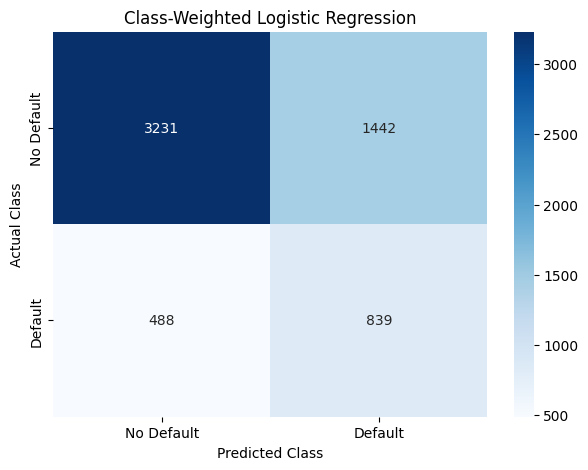

In [ ]:

cm_balanced = confusion_matrix(y_test, y_pred_balanced)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_balanced,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Class-Weighted Logistic Regression")
plt.show()


# **Random Forest Model Development**

In [ ]:

from sklearn.ensemble import RandomForestClassifier

print("Random Forest imported successfully!")


Random Forest imported successfully!


In [ ]:

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        )
    ]
)

print("Random Forest preprocessing created!")


Random Forest preprocessing created!


In [ ]:

rf_model = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")


Random Forest trained successfully!


In [ ]:

# Predict probabilities
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Predict default/non-default using 0.5 threshold
y_pred_rf = (y_prob_rf >= 0.50).astype(int)

print("Random Forest predictions generated!")

print("\nFirst 10 default probabilities:")
print(y_prob_rf[:10])


Random Forest predictions generated!

First 10 default probabilities:
[0.13212393 0.18440076 0.16869444 0.18014724 0.00922222 0.42092063
 0.10116942 0.01       0.10645238 0.07422222]


In [ ]:

print("Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Precision:",
      precision_score(y_test, y_pred_rf))

print("Recall:",
      recall_score(y_test, y_pred_rf))

print("F1 Score:",
      f1_score(y_test, y_pred_rf))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))


Accuracy: 0.8171666666666667
Precision: 0.657103825136612
Recall: 0.3624717407686511
F1 Score: 0.46721709567751335
ROC-AUC: 0.7647568460351446

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.36      0.47      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.68      6000
weighted avg       0.80      0.82      0.80      6000



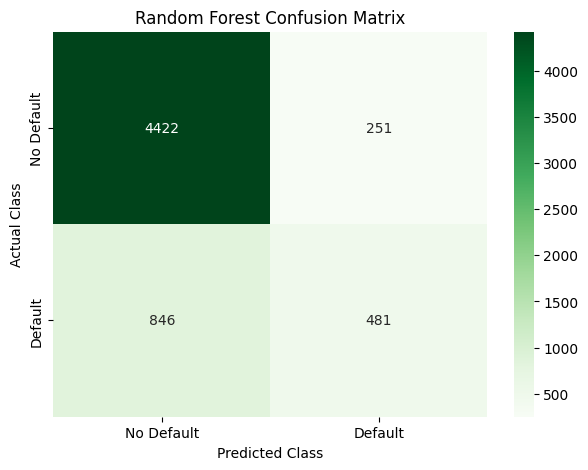

In [ ]:

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest Confusion Matrix")

plt.show()


# **ROC Curve and AUC for Random Forest**

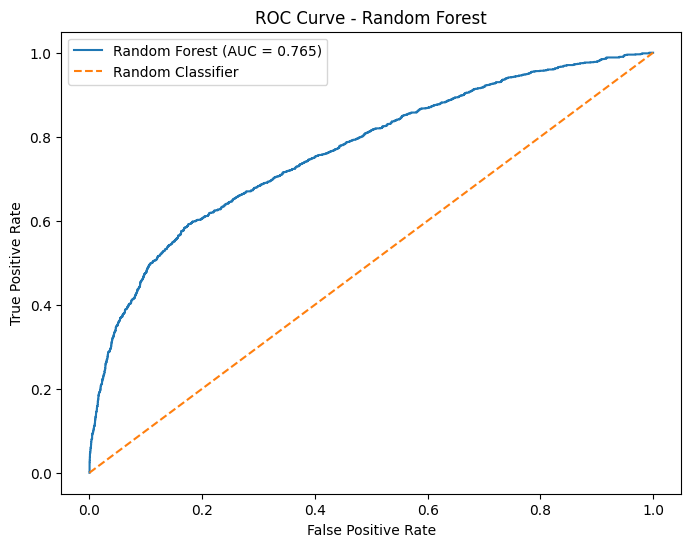

Random Forest ROC-AUC: 0.7647568460351446


In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr_rf, tpr_rf, thresholds_rf = roc_curve(
    y_test,
    y_prob_rf
)

# Calculate AUC
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()

plt.show()

print("Random Forest ROC-AUC:", auc_rf)


# **ROC-AUC Comparison of Three Models**

---



In [ ]:

# Calculate balanced Logistic Regression AUC
auc_balanced = roc_auc_score(
    y_test,
    y_prob_balanced
)

# Compare models
model_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest"
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob),
        auc_balanced,
        auc_rf
    ]
})

print(model_comparison)


                          Model   ROC_AUC
0  Original Logistic Regression  0.709856
1  Balanced Logistic Regression  0.710485
2                 Random Forest  0.764757


In [ ]:

performance_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_rf)
    ],
    "F1_Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC_AUC": [
        roc_auc_score(y_test, y_prob),
        auc_balanced,
        auc_rf
    ]
})

print(performance_comparison.round(4))


                          Model  Accuracy  Precision  Recall  F1_Score  \
0  Original Logistic Regression    0.8087     0.6908  0.2442    0.3608   
1  Balanced Logistic Regression    0.6783     0.3678  0.6323    0.4651   
2                 Random Forest    0.8172     0.6571  0.3625    0.4672   

   ROC_AUC  
0   0.7099  
1   0.7105  
2   0.7648  


# **Class-Weighted Random Forest Model**

In [ ]:

# Create class-weighted Random Forest
rf_balanced = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train the model
rf_balanced.fit(X_train, y_train)

print("Class-weighted Random Forest trained successfully!")


Class-weighted Random Forest trained successfully!


# **Performance Evaluation of Class-Weighted Random Forest**

In [ ]:

# Predict default probabilities
y_prob_rf_balanced = rf_balanced.predict_proba(X_test)[:, 1]

# Predict classes using 0.50 threshold
y_pred_rf_balanced = (
    y_prob_rf_balanced >= 0.50
).astype(int)

# Calculate performance metrics
print("Accuracy:",
      accuracy_score(y_test, y_pred_rf_balanced))

print("Precision:",
      precision_score(y_test, y_pred_rf_balanced))

print("Recall:",
      recall_score(y_test, y_pred_rf_balanced))

print("F1 Score:",
      f1_score(y_test, y_pred_rf_balanced))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_rf_balanced))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf_balanced))


Accuracy: 0.8103333333333333
Precision: 0.6006389776357828
Recall: 0.4250188394875659
F1 Score: 0.4977934686672551
ROC-AUC: 0.7680897380468631

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.92      0.88      4673
           1       0.60      0.43      0.50      1327

    accuracy                           0.81      6000
   macro avg       0.72      0.67      0.69      6000
weighted avg       0.79      0.81      0.80      6000



# **Confusion Matrix of Class-Weighted Random Forest**

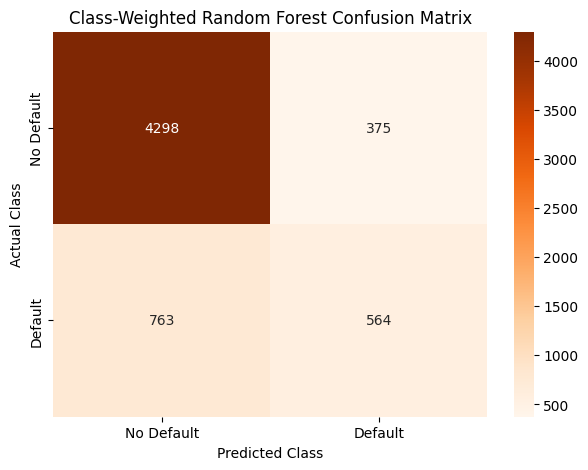

In [ ]:

cm_rf_balanced = confusion_matrix(
    y_test,
    y_pred_rf_balanced
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_rf_balanced,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Class-Weighted Random Forest Confusion Matrix")

plt.show()


# **Final Model Comparison**

In [ ]:

final_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest",
        "Balanced Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_balanced)
    ],

    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf_balanced)
    ],

    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf_balanced)
    ],

    "F1_Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf_balanced)
    ],

    "ROC_AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob_balanced),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_rf_balanced)
    ]
})

print(final_comparison.round(4))


                          Model  Accuracy  Precision  Recall  F1_Score  \
0  Original Logistic Regression    0.8087     0.6908  0.2442    0.3608   
1  Balanced Logistic Regression    0.6783     0.3678  0.6323    0.4651   
2                 Random Forest    0.8172     0.6571  0.3625    0.4672   
3        Balanced Random Forest    0.8103     0.6006  0.4250    0.4978   

   ROC_AUC  
0   0.7099  
1   0.7105  
2   0.7648  
3   0.7681  


# **Feature Importance Analysis using Balanced Random Forest**

In [ ]:

# Extract trained Random Forest model
rf_classifier = rf_balanced.named_steps["classifier"]

# Get transformed feature names
feature_names = (
    rf_balanced
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Extract feature importance
importance_values = rf_classifier.feature_importances_

# Create importance DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Important Features:")
print(feature_importance.head(15))


Top 15 Important Features:
           Feature  Importance
2       num__PAY_0    0.105875
8   num__BILL_AMT1    0.059051
0   num__LIMIT_BAL    0.057425
14   num__PAY_AMT1    0.053524
1         num__AGE    0.052420
15   num__PAY_AMT2    0.052119
9   num__BILL_AMT2    0.052026
16   num__PAY_AMT3    0.049514
10  num__BILL_AMT3    0.049345
13  num__BILL_AMT6    0.047984
11  num__BILL_AMT4    0.047773
12  num__BILL_AMT5    0.047361
3       num__PAY_2    0.046777
19   num__PAY_AMT6    0.045278
17   num__PAY_AMT4    0.044254


# **Top 15 Credit Default Predictors**

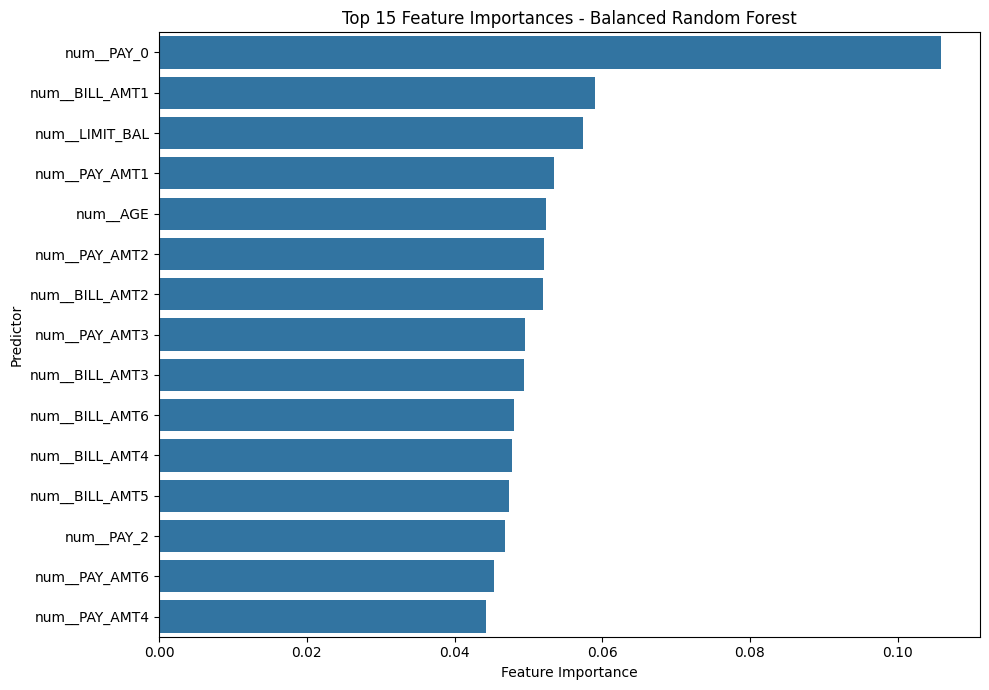

In [ ]:

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances - Balanced Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()


# **Permutation Feature Importance**

In [ ]:

from sklearn.inspection import permutation_importance

# Calculate permutation importance
perm_importance = permutation_importance(
    rf_balanced,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

# Create results DataFrame
permutation_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean,
    "Std": perm_importance.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 15 Permutation Importances:")
print(permutation_df.head(15))


Top 15 Permutation Importances:
      Feature  Importance       Std
5       PAY_0    0.072171  0.002831
0   LIMIT_BAL    0.018527  0.001599
11  BILL_AMT1    0.010298  0.001304
6       PAY_2    0.007856  0.002736
17   PAY_AMT1    0.004813  0.001392
7       PAY_3    0.004594  0.002092
18   PAY_AMT2    0.003964  0.001534
22   PAY_AMT6    0.003256  0.000648
10      PAY_6    0.002560  0.001813
8       PAY_4    0.002542  0.002430
4         AGE    0.002447  0.000969
9       PAY_5    0.001994  0.001536
19   PAY_AMT3    0.001688  0.000508
13  BILL_AMT3    0.001630  0.001052
3    MARRIAGE    0.001606  0.000600


# **Permutation Importance Visualisation**

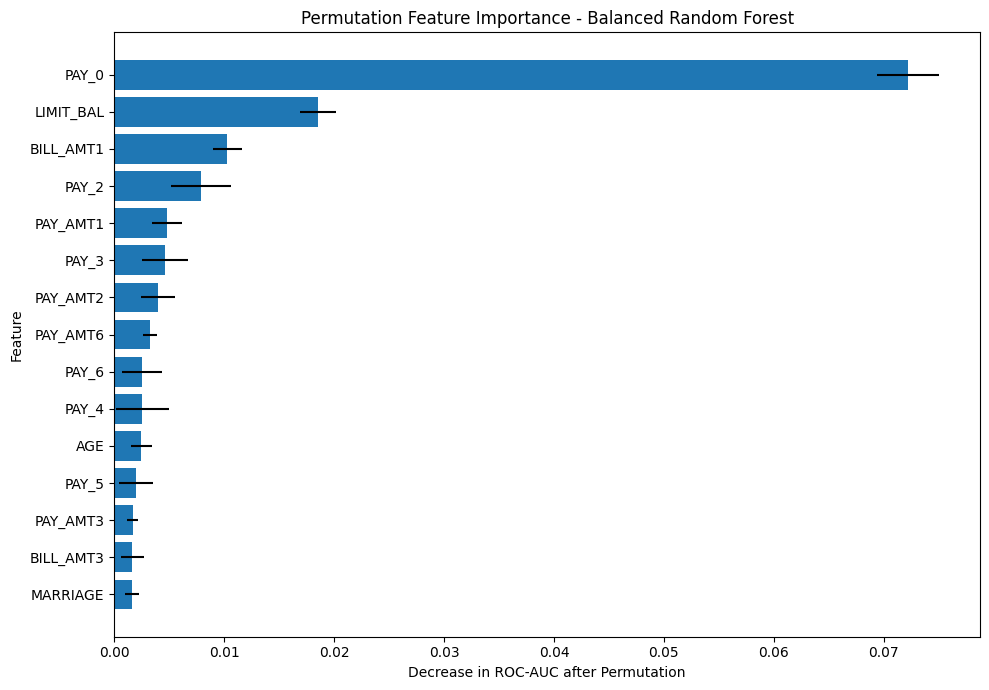

In [ ]:

top_perm = permutation_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_perm["Feature"],
    top_perm["Importance"],
    xerr=top_perm["Std"]
)

plt.xlabel("Decrease in ROC-AUC after Permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - Balanced Random Forest")

plt.tight_layout()
plt.show()


# **Credit Risk Segmentation**

In [ ]:

# Create a copy of the test data
risk_analysis = X_test.copy()

risk_analysis["ACTUAL_DEFAULT"] = y_test.values

# Add predicted risk scores
risk_analysis["RISK_SCORE"] = y_prob_rf_balanced

# Assign risk categories
def classify_risk(score):
    if score < 0.20:
        return "Low Risk"
    elif score < 0.50:
        return "Medium Risk"
    else:
        return "High Risk"

risk_analysis["RISK_CATEGORY"] = (
    risk_analysis["RISK_SCORE"].apply(classify_risk)
)

print(risk_analysis[
    ["RISK_SCORE", "RISK_CATEGORY", "ACTUAL_DEFAULT"]
].head(10))


       RISK_SCORE RISK_CATEGORY  ACTUAL_DEFAULT
6907     0.175382      Low Risk               0
24575    0.258979   Medium Risk               0
26766    0.246040   Medium Risk               0
2156     0.206185   Medium Risk               1
3179     0.030532      Low Risk               0
29382    0.361360   Medium Risk               0
24454    0.108568      Low Risk               0
23886    0.019426      Low Risk               0
5504     0.147012      Low Risk               0
29720    0.079275      Low Risk               0


# **Risk Category Analysis**

In [ ]:

risk_summary = (
    risk_analysis.groupby("RISK_CATEGORY")
    .agg(
        Customer_Count=("ACTUAL_DEFAULT", "count"),
        Average_Risk_Score=("RISK_SCORE", "mean"),
        Actual_Default_Rate=("ACTUAL_DEFAULT", "mean")
    )
)

risk_summary["Actual_Default_Rate"] *= 100

print(risk_summary.round(2))


               Customer_Count  Average_Risk_Score  Actual_Default_Rate
RISK_CATEGORY                                                         
High Risk                 939                0.68                60.06
Low Risk                 3127                0.12                10.46
Medium Risk              1934                0.30                22.54


# **Customer Distribution Across Risk Categories**

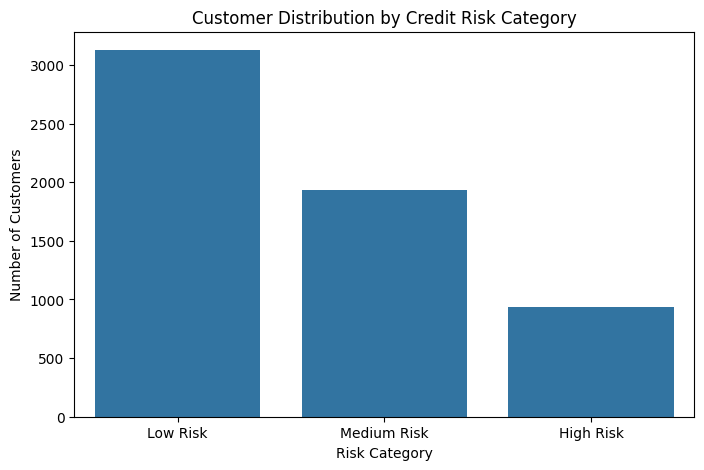

In [ ]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=risk_analysis,
    x="RISK_CATEGORY",
    order=["Low Risk", "Medium Risk", "High Risk"]
)

plt.title("Customer Distribution by Credit Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")

plt.show()


# **Actual Default Rate by Risk Category**

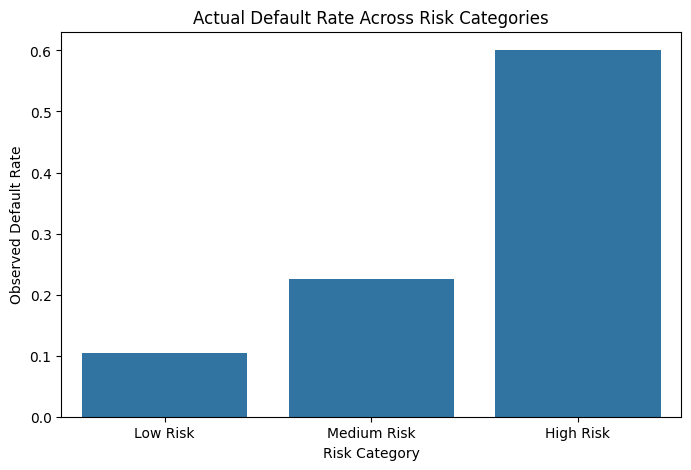

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=risk_analysis,
    x="RISK_CATEGORY",
    y="ACTUAL_DEFAULT",
    order=["Low Risk", "Medium Risk", "High Risk"],
    errorbar=None
)

plt.title("Actual Default Rate Across Risk Categories")
plt.xlabel("Risk Category")
plt.ylabel("Observed Default Rate")

plt.show()


# **Illustrative Expected Credit Loss Calculation**

In [ ]:

# Explicit illustrative assumptions
assumed_lgd = 0.45

# Use credit limit only as an exposure proxy
risk_analysis["ASSUMED_LGD"] = assumed_lgd

risk_analysis["ILLUSTRATIVE_EL"] = (
    risk_analysis["RISK_SCORE"]
    * risk_analysis["ASSUMED_LGD"]
    * risk_analysis["LIMIT_BAL"]
)

print("Total illustrative expected loss:",
      risk_analysis["ILLUSTRATIVE_EL"].sum())

print("\nAverage illustrative expected loss:",
      risk_analysis["ILLUSTRATIVE_EL"].mean())


Total illustrative expected loss: 97378118.7409981

Average illustrative expected loss: 16229.686456833017


# **Credit Risk Segmentation Summary**

In [ ]:

risk_summary = (
    risk_analysis.groupby("RISK_CATEGORY")
    .agg(
        Customer_Count=("ACTUAL_DEFAULT", "count"),
        Average_Risk_Score=("RISK_SCORE", "mean"),
        Actual_Default_Rate=("ACTUAL_DEFAULT", "mean")
    )
    .reindex(["Low Risk", "Medium Risk", "High Risk"])
)

risk_summary["Actual_Default_Rate"] *= 100

print(risk_summary.round(2))


               Customer_Count  Average_Risk_Score  Actual_Default_Rate
RISK_CATEGORY                                                         
Low Risk                 3127                0.12                10.46
Medium Risk              1934                0.30                22.54
High Risk                 939                0.68                60.06


# **Observed Default Rate by Risk Category**

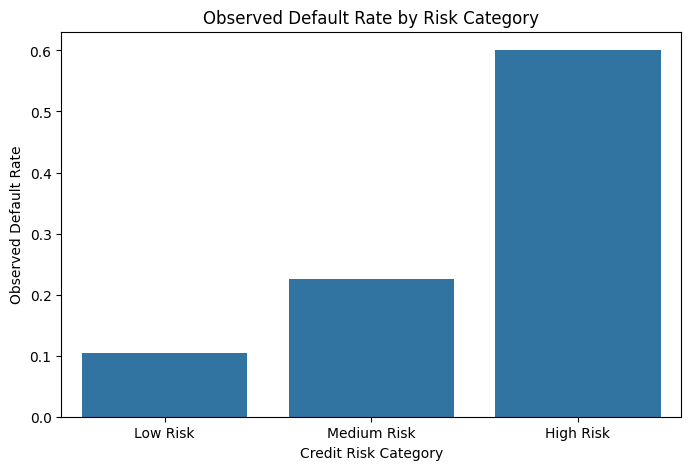

In [ ]:

plt.figure(figsize=(8, 5))

sns.barplot(
    data=risk_analysis,
    x="RISK_CATEGORY",
    y="ACTUAL_DEFAULT",
    order=["Low Risk", "Medium Risk", "High Risk"],
    errorbar=None
)

plt.title("Observed Default Rate by Risk Category")
plt.xlabel("Credit Risk Category")
plt.ylabel("Observed Default Rate")

plt.show()


# **Probability Calibration of Balanced Random Forest**

In [ ]:

from sklearn.calibration import CalibratedClassifierCV

# Calibrate the balanced Random Forest
calibrated_rf = CalibratedClassifierCV(
    estimator=rf_balanced,
    method="sigmoid",
    cv=5
)

# Fit using training data only
calibrated_rf.fit(X_train, y_train)

print("Probability calibration completed!")


Probability calibration completed!


# **Reliability Diagram for Default Probability**

Brier Score: 0.1366
Mean Predicted Probability: 0.221
Actual Default Rate: 0.2212


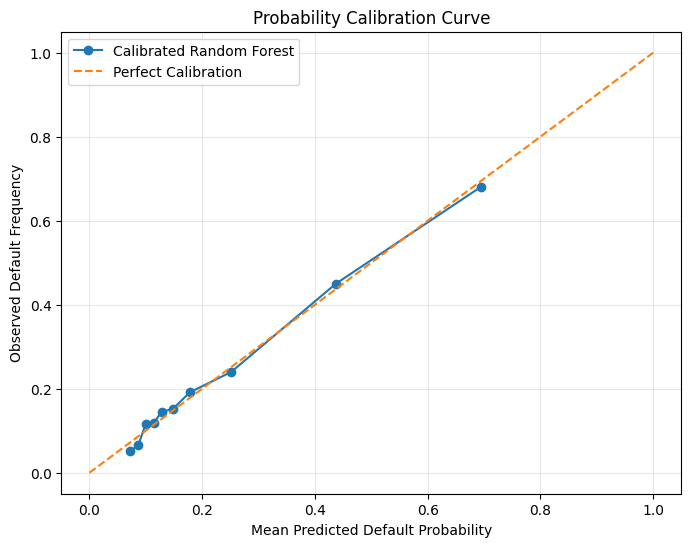

In [ ]:

# Import calibration tools
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

# Generate calibrated probabilities if not already generated
y_prob_calibrated = calibrated_rf.predict_proba(X_test)[:, 1]

# Calculate calibration curve
prob_true, prob_pred = calibration_curve(
    y_test,
    y_prob_calibrated,
    n_bins=10,
    strategy="quantile"
)

# Calculate Brier score
brier = brier_score_loss(y_test, y_prob_calibrated)

print("Brier Score:", round(brier, 4))
print("Mean Predicted Probability:", round(y_prob_calibrated.mean(), 4))
print("Actual Default Rate:", round(y_test.mean(), 4))

# Plot calibration curve
plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Calibrated Random Forest"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Default Probability")
plt.ylabel("Observed Default Frequency")
plt.title("Probability Calibration Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


# **Calibrated Credit Risk Segmentation**

In [ ]:

# Create risk analysis dataset
calibrated_risk = X_test.copy()

calibrated_risk["ACTUAL_DEFAULT"] = y_test.values
calibrated_risk["PREDICTED_PD"] = y_prob_calibrated

# Assign risk categories
def assign_risk_category(pd_value):
    if pd_value < 0.20:
        return "Low Risk"
    elif pd_value < 0.50:
        return "Medium Risk"
    else:
        return "High Risk"

calibrated_risk["RISK_CATEGORY"] = (
    calibrated_risk["PREDICTED_PD"].apply(assign_risk_category)
)

print(calibrated_risk[
    ["PREDICTED_PD", "RISK_CATEGORY", "ACTUAL_DEFAULT"]
].head(10))


       PREDICTED_PD RISK_CATEGORY  ACTUAL_DEFAULT
6907       0.131326      Low Risk               0
24575      0.164732      Low Risk               0
26766      0.143283      Low Risk               0
2156       0.129754      Low Risk               1
3179       0.064087      Low Risk               0
29382      0.274837   Medium Risk               0
24454      0.099332      Low Risk               0
23886      0.061558      Low Risk               0
5504       0.116641      Low Risk               0
29720      0.090733      Low Risk               0


# **Final Evaluation of Calibrated Random Forest**

In [ ]:

# Class predictions from calibrated probabilities
y_pred_calibrated = (
    y_prob_calibrated >= 0.50
).astype(int)

# Final evaluation metrics
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_calibrated),
    "Precision": precision_score(y_test, y_pred_calibrated),
    "Recall": recall_score(y_test, y_pred_calibrated),
    "F1 Score": f1_score(y_test, y_pred_calibrated),
    "ROC-AUC": roc_auc_score(y_test, y_prob_calibrated),
    "Brier Score": brier_score_loss(y_test, y_prob_calibrated)
}

print("FINAL CALIBRATED MODEL PERFORMANCE")

for metric, value in final_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred_calibrated))


FINAL CALIBRATED MODEL PERFORMANCE
Accuracy: 0.8153
Precision: 0.6474
Recall: 0.3625
F1 Score: 0.4647
ROC-AUC: 0.7698
Brier Score: 0.1366

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.65      0.36      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.74      0.65      0.68      6000
weighted avg       0.80      0.82      0.79      6000



# **Final Confusion Matrix of Calibrated Random Forest**

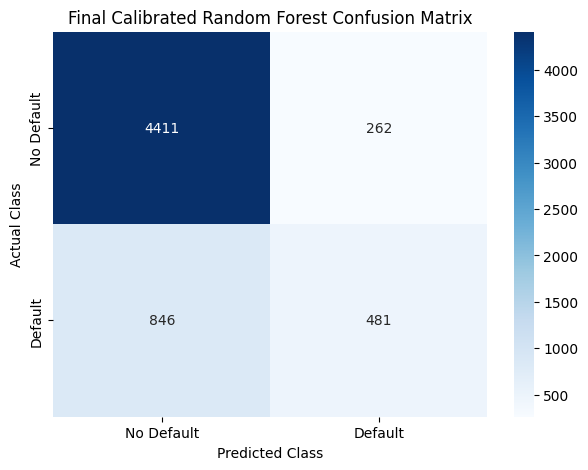

In [ ]:

cm_final = confusion_matrix(
    y_test,
    y_pred_calibrated
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Default", "Default"],
    yticklabels=["No Default", "Default"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Final Calibrated Random Forest Confusion Matrix")

plt.show()


# **Credit Risk Classification Impact Analysis**

In [ ]:

tn, fp, fn, tp = cm_final.ravel()

total_customers = len(y_test)

print("Total customers:", total_customers)

print("Correctly identified defaulters:", tp)
print("Missed defaulters:", fn)
print("Incorrectly flagged non-defaulters:", fp)
print("Correctly identified non-defaulters:", tn)

print("\nPercentage of actual defaulters identified:",
      round(tp / (tp + fn) * 100, 2), "%")

print("Percentage of actual defaulters missed:",
      round(fn / (tp + fn) * 100, 2), "%")

print("False positive rate:",
      round(fp / (fp + tn) * 100, 2), "%")


Total customers: 6000
Correctly identified defaulters: 481
Missed defaulters: 846
Incorrectly flagged non-defaulters: 262
Correctly identified non-defaulters: 4411

Percentage of actual defaulters identified: 36.25 %
Percentage of actual defaulters missed: 63.75 %
False positive rate: 5.61 %


# **Model Limitations and Risk Considerations**

In [ ]:

limitations = [
    "The dataset contains historical customer information and "
    "may not represent current borrower behaviour.",

    "The default outcome is binary and does not capture the "
    "severity or timing of credit losses.",

    "Credit limit is not equivalent to actual exposure at default.",

    "LGD was assumed for the illustrative expected-loss exercise.",

    "Class weighting can alter the interpretation of predicted "
    "probabilities.",

    "The model has not been independently validated on an "
    "external dataset.",

    "Potential data leakage, population drift and fairness "
    "concerns require further investigation.",

    "The test set has been used repeatedly during exploratory "
    "model comparisons, so its results are not a fully untouched "
    "final performance estimate."
]

for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")


1. The dataset contains historical customer information and may not represent current borrower behaviour.
2. The default outcome is binary and does not capture the severity or timing of credit losses.
3. Credit limit is not equivalent to actual exposure at default.
4. LGD was assumed for the illustrative expected-loss exercise.
5. Class weighting can alter the interpretation of predicted probabilities.
6. The model has not been independently validated on an external dataset.
7. Potential data leakage, population drift and fairness concerns require further investigation.
8. The test set has been used repeatedly during exploratory model comparisons, so its results are not a fully untouched final performance estimate.


# **Prepare Data for Final Model Validation**

In [ ]:

# Use original predictors, excluding engineered features
X_final = df.drop(
    columns=[
        "DEFAULT",
        "AGE_GROUP",
        "CREDIT_UTILIZATION",
        "DELAY_MONTHS",
        "PAYMENT_TO_BILL_RATIO"
    ],
    errors="ignore"
).copy()

y_final = df["DEFAULT"].copy()

print("Predictor dimensions:", X_final.shape)
print("Target dimensions:", y_final.shape)


Predictor dimensions: (30000, 23)
Target dimensions: (30000,)


# **Stratified Train Validation Test Split**

In [ ]:

# First, separate the final test set (15%)
X_remaining, X_test_final, y_remaining, y_test_final = (
    train_test_split(
        X_final,
        y_final,
        test_size=0.15,
        random_state=42,
        stratify=y_final
    )
)

# Divide remaining data into training (70%) and validation (15%)
X_train_final, X_val_final, y_train_final, y_val_final = (
    train_test_split(
        X_remaining,
        y_remaining,
        test_size=0.176470588,
        random_state=42,
        stratify=y_remaining
    )
)

print("Training records:", len(X_train_final))
print("Validation records:", len(X_val_final))
print("Test records:", len(X_test_final))

print("\nDefault rates:")
print("Training:", round(y_train_final.mean() * 100, 2), "%")
print("Validation:", round(y_val_final.mean() * 100, 2), "%")
print("Test:", round(y_test_final.mean() * 100, 2), "%")


Training records: 21000
Validation records: 4500
Test records: 4500

Default rates:
Training: 22.12 %
Validation: 22.11 %
Test: 22.11 %


# **Train Final Calibrated Random Forest**

In [ ]:

# Recreate the balanced Random Forest pipeline
final_rf_pipeline = Pipeline([
    ("preprocessor", rf_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Calibrate using training data only
final_calibrated_rf = CalibratedClassifierCV(
    estimator=final_rf_pipeline,
    method="sigmoid",
    cv=5
)

final_calibrated_rf.fit(
    X_train_final,
    y_train_final
)

print("Final model trained and calibrated!")


Final model trained and calibrated!


# **Classification Threshold Selection**

In [ ]:

# Predict validation probabilities
val_prob = final_calibrated_rf.predict_proba(
    X_val_final
)[:, 1]

# Evaluate several candidate thresholds
threshold_results = []

for threshold in np.arange(0.10, 0.71, 0.05):

    val_pred = (val_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_final, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val_final, val_pred, zero_division=0
        ),
        "F1_Score": f1_score(
            y_val_final, val_pred, zero_division=0
        )
    })

threshold_table = pd.DataFrame(threshold_results)

print(threshold_table.round(4))

best_threshold = threshold_table.loc[
    threshold_table["F1_Score"].idxmax(),
    "Threshold"
]

print("\nSelected validation threshold:", best_threshold)


    Threshold  Precision  Recall  F1_Score
0        0.10     0.2717  0.9246    0.4200
1        0.15     0.3790  0.7457    0.5025
2        0.20     0.4679  0.6221    0.5341
3        0.25     0.5334  0.5698    0.5510
4        0.30     0.5628  0.5176    0.5393
5        0.35     0.5912  0.4724    0.5251
6        0.40     0.6188  0.4372    0.5124
7        0.45     0.6424  0.3899    0.4853
8        0.50     0.6798  0.3457    0.4584
9        0.55     0.7064  0.2975    0.4187
10       0.60     0.7284  0.2452    0.3669
11       0.65     0.7520  0.1889    0.3020
12       0.70     0.7821  0.1407    0.2385

Selected validation threshold: 0.25000000000000006


# **Final Out-of-Sample Model Evaluation**

In [ ]:

# Evaluate exactly once on the final test set
test_prob_final = final_calibrated_rf.predict_proba(
    X_test_final
)[:, 1]

test_pred_final = (
    test_prob_final >= best_threshold
).astype(int)

print("FINAL TEST RESULTS")

print("Accuracy:",
      accuracy_score(y_test_final, test_pred_final))

print("Precision:",
      precision_score(y_test_final, test_pred_final))

print("Recall:",
      recall_score(y_test_final, test_pred_final))

print("F1 Score:",
      f1_score(y_test_final, test_pred_final))

print("ROC-AUC:",
      roc_auc_score(y_test_final, test_prob_final))

print("Brier Score:",
      brier_score_loss(y_test_final, test_prob_final))

print("\nClassification Report:")
print(classification_report(y_test_final, test_pred_final))


FINAL TEST RESULTS
Accuracy: 0.786
Precision: 0.5148423005565863
Recall: 0.5577889447236181
F1 Score: 0.5354558610709117
ROC-AUC: 0.7727120624520607
Brier Score: 0.13573565559106843

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      3505
           1       0.51      0.56      0.54       995

    accuracy                           0.79      4500
   macro avg       0.69      0.70      0.70      4500
weighted avg       0.79      0.79      0.79      4500



**Final Test Confusion Matrix**

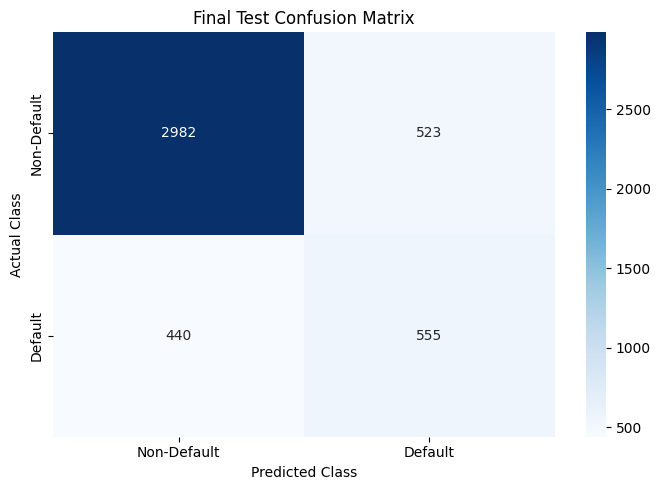

True Negatives: 2982
False Positives: 523
False Negatives: 440
True Positives: 555


In [ ]:

cm_final_test = confusion_matrix(
    y_test_final,
    test_pred_final
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_final_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Default", "Default"],
    yticklabels=["Non-Default", "Default"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Final Test Confusion Matrix")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_final_test.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)


# **Save Final Credit Risk Model**

In [ ]:

import joblib

model_artifact = {
    "model": final_calibrated_rf,
    "threshold": float(best_threshold),
    "features": X_train_final.columns.tolist(),
    "model_name": "Calibrated Random Forest",
    "roc_auc": float(
        roc_auc_score(y_test_final, test_prob_final)
    ),
    "brier_score": float(
        brier_score_loss(y_test_final, test_prob_final)
    )
}

joblib.dump(
    model_artifact,
    "credit_risk_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!


In [ ]:

from google.colab import files

files.download("credit_risk_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC",
        "Brier Score",
        "Selected Threshold"
    ],
    "Value": [
        accuracy_score(y_test_final, test_pred_final),
        precision_score(y_test_final, test_pred_final),
        recall_score(y_test_final, test_pred_final),
        f1_score(y_test_final, test_pred_final),
        roc_auc_score(y_test_final, test_prob_final),
        brier_score_loss(y_test_final, test_prob_final),
        best_threshold
    ]
})

final_results.to_csv(
    "final_model_evaluation.csv",
    index=False
)

print(final_results.round(4))


               Metric   Value
0            Accuracy  0.7860
1           Precision  0.5148
2              Recall  0.5578
3            F1 Score  0.5355
4             ROC-AUC  0.7727
5         Brier Score  0.1357
6  Selected Threshold  0.2500


In [ ]:

# Export cleaned dataset
df_clean.to_csv(
    "credit_risk_cleaned_data.csv",
    index=False
)

# Download CSV to your computer
from google.colab import files

files.download("credit_risk_cleaned_data.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>